# Tutorial Class 05 Set 01

In [6]:
library(tidyverse)

## Prepare these Exercises before Class

### Exercise 1

In [7]:
asx_prices_messy <- read_csv("../../../../data/asx_prices_messy.csv")

Rows: 2003 Columns: 14
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (2): gvkey, conm
dbl (12): price_2019, price_2020, price_2021, price_2022, price_2023, price_...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [8]:
asx_prices_messy |>
  select(gvkey, conm, price_2023, price_2024, eps_2023, eps_2024) |> 
  head(10)

gvkey,conm,price_2023,price_2024,eps_2023,eps_2024
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
272690,1300 SMILES LTD,NA,NA,NA,NA
327267,1414 DEGREES LTD,0.040,0.067,-0.0091,-0.0107
349318,29METALS LIMITED,0.375,NA,-0.7986,NA
284698,3D ENERGI LIMITED,0.056,0.070,0.0129,-0.0075
346142,3D METALFORGE LIMITED,NA,NA,NA,NA
317959,3P LEARNING LTD,1.270,1.020,0.0230,-0.2077
253413,3Q HOLDINGS LTD,NA,NA,NA,NA
339106,4DMEDICAL LTD,0.450,0.675,-0.1049,-0.0971
314650,4DS MEMORY LTD,0.135,0.084,-0.0038,-0.0031


In [9]:
asx_prices_messy |>
  summarise(
    # Add up all 2023 share prices
    sum_prices_2023 = sum(price_2023, na.rm = TRUE),
    # Add up all 2024 share prices
    sum_prices_2024 = sum(price_2024, na.rm = TRUE),
    # Count how many firms have a non-missing share price in 2023
    count_firms_2023 = sum(!is.na(price_2023)),
    # Count how many firms have a non-missing share price in 2024
    count_firms_2024 = sum(!is.na(price_2024))
  ) |>
  mutate(
    # Combine the 2023 and 2024 price totals
    total_sum = sum_prices_2023 + sum_prices_2024,
    # Combine the number of non-missing firm prices across both years
    total_count = count_firms_2023 + count_firms_2024
  ) |>
  mutate(
    # Divide the total sum of prices by the total number of firms
    avg_price_23_24 = total_sum / total_count
  ) |> 
  select(avg_price_23_24)

avg_price_23_24
<dbl>
2.765119


`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 19 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 19 rows containing missing values or values outside the scale range
(`geom_point()`).”


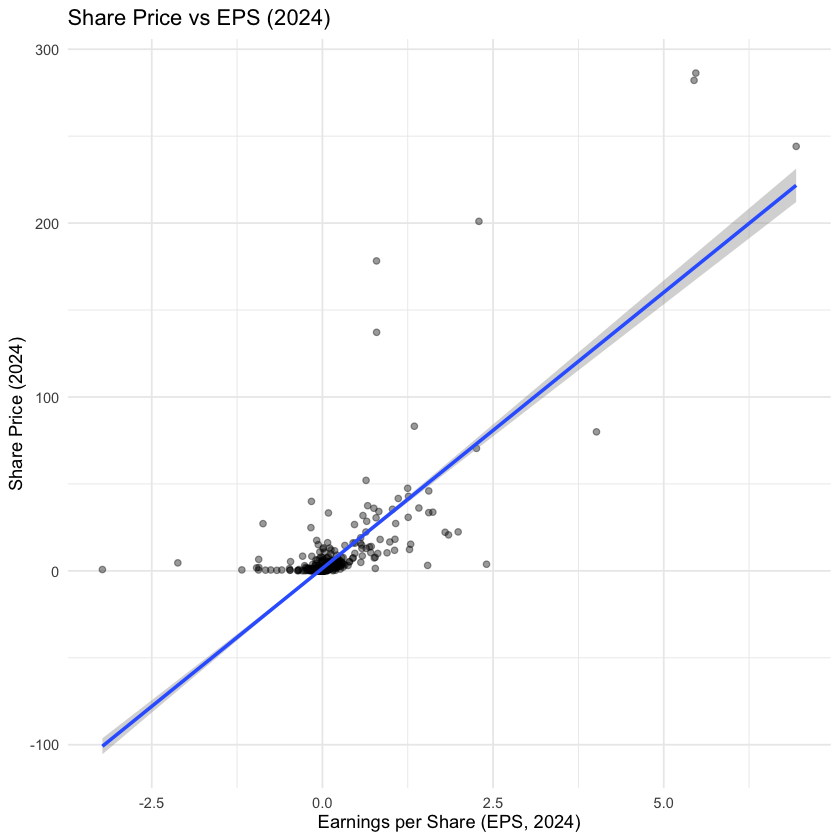

In [10]:
asx_prices_messy |>
  filter(eps_2024 > -5) |>
  ggplot(aes(x = eps_2024, y = price_2024)) +
  geom_point(alpha = 0.4) +
  geom_smooth(method = "lm", se = TRUE) +
  labs(
    title = "Share Price vs EPS (2024)",
    x = "Earnings per Share (EPS, 2024)",
    y = "Share Price (2024)"
  ) +
  theme_minimal()

### Exercise 2

In [11]:
firm_codes <-
  read_csv("../../../../data/asx_200_2024.csv") |>
  select(gvkey, conm, gsubind)

subindustry_names <-
  read_csv("../../../../data/GICS_subindustry.csv")

Rows: 200 Columns: 30
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (10): gvkey, curcd, datadate, conm, fic, conml, sector, indgroup, indust...
dbl (20): fyear, fyr, at, capx, shareequity, dlc, dltt, dvp, ebit, netprofit...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 170 Columns: 2
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (1): subind
dbl (1): gsubind

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [12]:
firm_codes |>
  head(10)

gvkey,conm,gsubind
<chr>,<chr>,<dbl>
013312,BHP GROUP LTD,15104020
210216,TELSTRA GROUP LIMITED,50101020
223003,CSL LTD,35201010
212650,TRANSURBAN GROUP,20305020
100894,WOOLWORTHS GROUP LTD,30101030
212427,FORTESCUE LTD,15104050
101601,WESFARMERS LTD,25503030
226744,RAMSAY HEALTH CARE LTD,35102020
220244,QANTAS AIRWAYS LTD,20302010


In [13]:
subindustry_names |>
  head(10)

gsubind,subind
<dbl>,<chr>
10101010,Oil & Gas Drilling
10101020,Oil & Gas Equipment & Services
10102010,Integrated Oil & Gas
10102020,Oil & Gas Exploration & Production
10102030,Oil & Gas Refining & Marketing
10102040,Oil & Gas Storage & Transportation
10102050,Coal & Consumable Fuels
15101010,Commodity Chemicals
15101020,Diversified Chemicals


In [14]:
firm_info <-
  firm_codes |>
  left_join(subindustry_names, by = join_by(gsubind))

firm_info |>
  head(10)

gvkey,conm,gsubind,subind
<chr>,<chr>,<dbl>,<chr>
013312,BHP GROUP LTD,15104020,Diversified Metals & Mining
210216,TELSTRA GROUP LIMITED,50101020,Integrated Telecommunication Services
223003,CSL LTD,35201010,Biotechnology
212650,TRANSURBAN GROUP,20305020,Highways & Railtracks
100894,WOOLWORTHS GROUP LTD,30101030,Food Retail
212427,FORTESCUE LTD,15104050,Steel
101601,WESFARMERS LTD,25503030,Broadline Retail (New)
226744,RAMSAY HEALTH CARE LTD,35102020,Health Care Facilities
220244,QANTAS AIRWAYS LTD,20302010,Passenger Airlines (New name)


In [15]:
subindustry_first <-
  subindustry_names |>
  left_join(firm_codes, by = join_by(gsubind))

subindustry_first |>
  head(10)

gsubind,subind,gvkey,conm
<dbl>,<chr>,<chr>,<chr>
10101010,Oil & Gas Drilling,NA,NA
10101020,Oil & Gas Equipment & Services,NA,NA
10102010,Integrated Oil & Gas,NA,NA
10102020,Oil & Gas Exploration & Production,101392,BEACH ENERGY LTD
10102020,Oil & Gas Exploration & Production,253322,AMPLITUDE ENERGY LIMITED
10102020,Oil & Gas Exploration & Production,271330,STRIKE ENERGY LTD
10102030,Oil & Gas Refining & Marketing,NA,NA
10102040,Oil & Gas Storage & Transportation,NA,NA
10102050,Coal & Consumable Fuels,284808,WHITEHAVEN COAL LIMITED


## In-Class Exercises

### Exercise 3

In [16]:
asx_prices_tidy <-
  asx_prices_messy |>
  pivot_longer(
    cols = starts_with("price") | starts_with("eps"),
    names_to = c(".value", "fyear"),
    names_sep = "_",
    values_drop_na = TRUE
  ) |>
  mutate(fyear = as.numeric(fyear))

asx_prices_tidy |>
  head(10)

gvkey,conm,fyear,price,eps
<chr>,<chr>,<dbl>,<dbl>,<dbl>
272690,1300 SMILES LTD,2019,6.280,0.3282
272690,1300 SMILES LTD,2020,6.110,0.3018
272690,1300 SMILES LTD,2021,8.100,0.4065
327267,1414 DEGREES LTD,2019,0.200,-0.0258
327267,1414 DEGREES LTD,2020,0.135,-0.0165
327267,1414 DEGREES LTD,2021,0.100,-0.0311
327267,1414 DEGREES LTD,2022,0.076,-0.0068
327267,1414 DEGREES LTD,2023,0.040,-0.0091
327267,1414 DEGREES LTD,2024,0.067,-0.0107


In [17]:
asx_prices_tidy |>
  filter(fyear %in% c(2023, 2024)) |>
  group_by(fyear) |>
  summarise(avg_price = mean(price, na.rm = TRUE))

fyear,avg_price
<dbl>,<dbl>
2023,2.746548
2024,2.788560


`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 208 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 208 rows containing missing values or values outside the scale range
(`geom_point()`).”


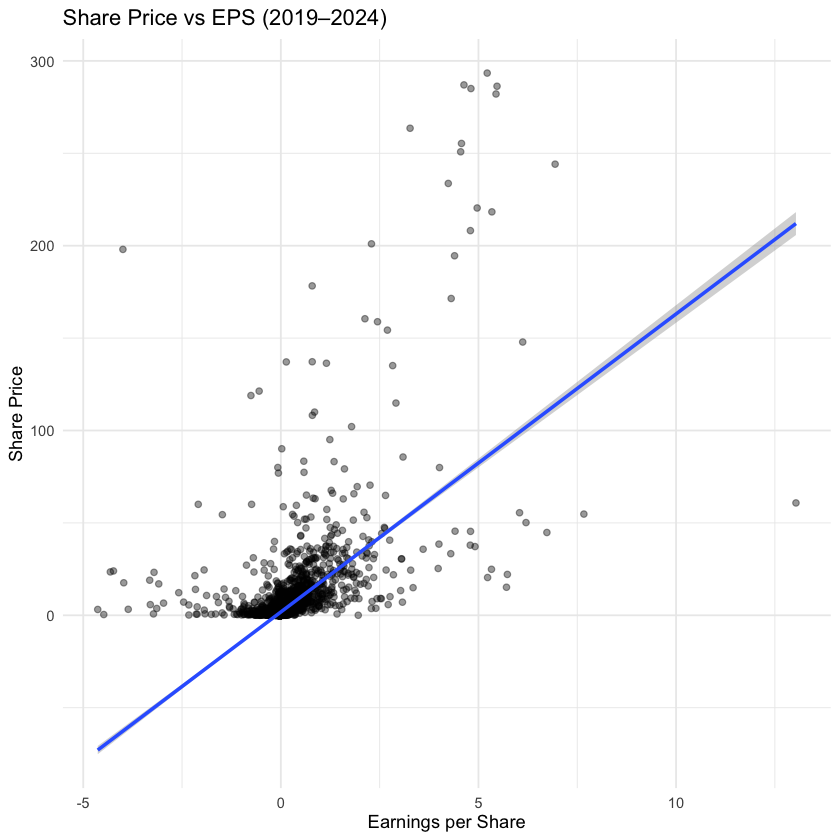

In [18]:
asx_prices_tidy |>
  filter(eps > -5) |>
  # create a scatterplot with EPS on the x-axis and price on the y-axis
  ggplot(aes(x = eps, y = price)) +
  # add points
  geom_point(alpha = 0.4) +
  # add a fitted straight line
  geom_smooth(method = "lm") +
  # add a title and axis labels
  labs(
    title = "Share Price vs EPS (2019–2024)",
    x = "Earnings per Share",
    y = "Share Price"
  ) +
  # use a theme
  theme_minimal()

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 50 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 50 rows containing missing values or values outside the scale range
(`geom_point()`).”


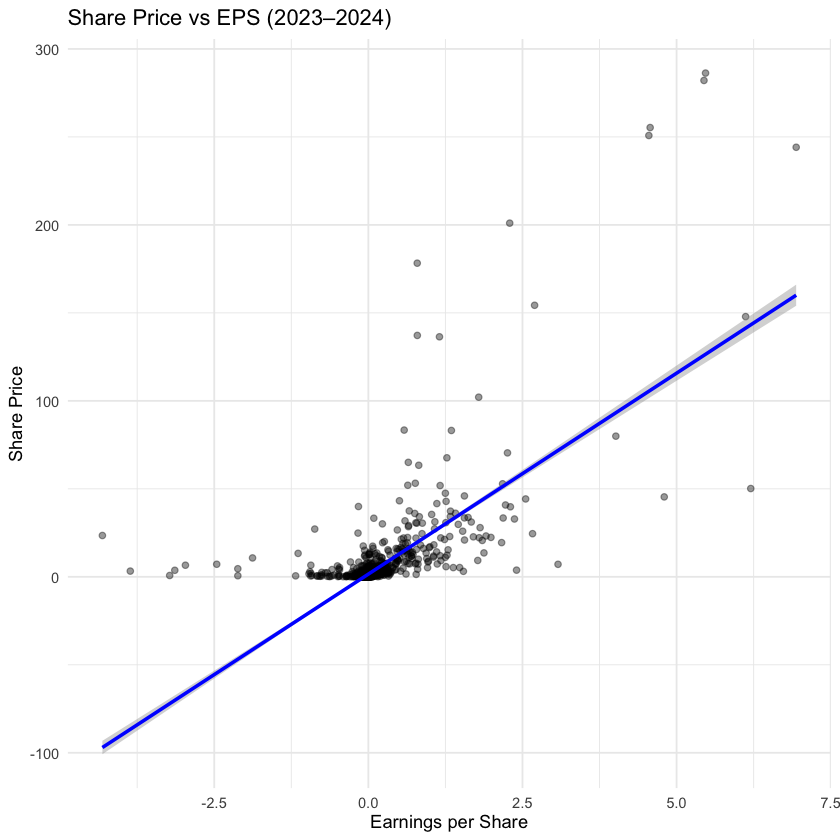

In [19]:
asx_prices_tidy |>
  filter(eps > -5) |>
  filter(fyear %in% c(2023, 2024)) |>
  # create a scatterplot with EPS on the x-axis and price on the y-axis
  ggplot(aes(x = eps, y = price)) +
  # add points
  geom_point(alpha = 0.4) +
  # add a fitted straight line
  geom_smooth(method = "lm", colour = "blue") +
  # add a title and axis labels
  labs(
    title = "Share Price vs EPS (2023–2024)",
    x = "Earnings per Share",
    y = "Share Price"
  ) +
  # use a theme
  theme_minimal()

### Exercise 4

In [23]:
pe_data <-
  read_csv("../../../../data/pe.csv") |>
  select(gvkey, fyear, pe) |>
  filter(!is.na(pe)) |>
  arrange(gvkey, fyear)

Rows: 40130 Columns: 7
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): gvkey, conm, datadate
dbl (4): fyear, price, eps, pe

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [24]:
asx_with_pe <-
  asx_prices_tidy |>
  left_join(
    pe_data,
    by = join_by(gvkey, fyear)
  )

In [25]:
asx_wrong_join <-
  asx_prices_tidy |>
  left_join(
    pe_data,
    by = join_by(gvkey)
  )

Warning message in left_join(asx_prices_tidy, pe_data, by = join_by(gvkey)):
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 1 of `x` matches multiple rows in `y`.
ℹ Row 6083 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”


In [26]:
asx_wrong_join <-
  asx_prices_tidy |>
  left_join(
    pe_data,
    by = join_by(gvkey)
  )

Warning message in left_join(asx_prices_tidy, pe_data, by = join_by(gvkey)):
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 1 of `x` matches multiple rows in `y`.
ℹ Row 6083 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”


### Exercise 5

In [27]:
asx_analysis <-
  asx_with_pe |>
  left_join(
    firm_info |> select(-conm),
    by = join_by(gvkey)
  )

In [28]:
industry_year_summary <-
  asx_analysis |>
  # remark adding subind just keeps us the human readable names
  group_by(gsubind, subind, fyear) |>
  summarise(
    avg_pe = mean(pe, na.rm = TRUE),
    avg_price = mean(price, na.rm = TRUE),
    avg_eps = mean(eps, na.rm = TRUE),
    n_firms = n()
  )

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by gsubind, subind, and fyear.
ℹ Output is grouped by gsubind and subind.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(gsubind, subind, fyear))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


`geom_smooth()` using formula = 'y ~ x'


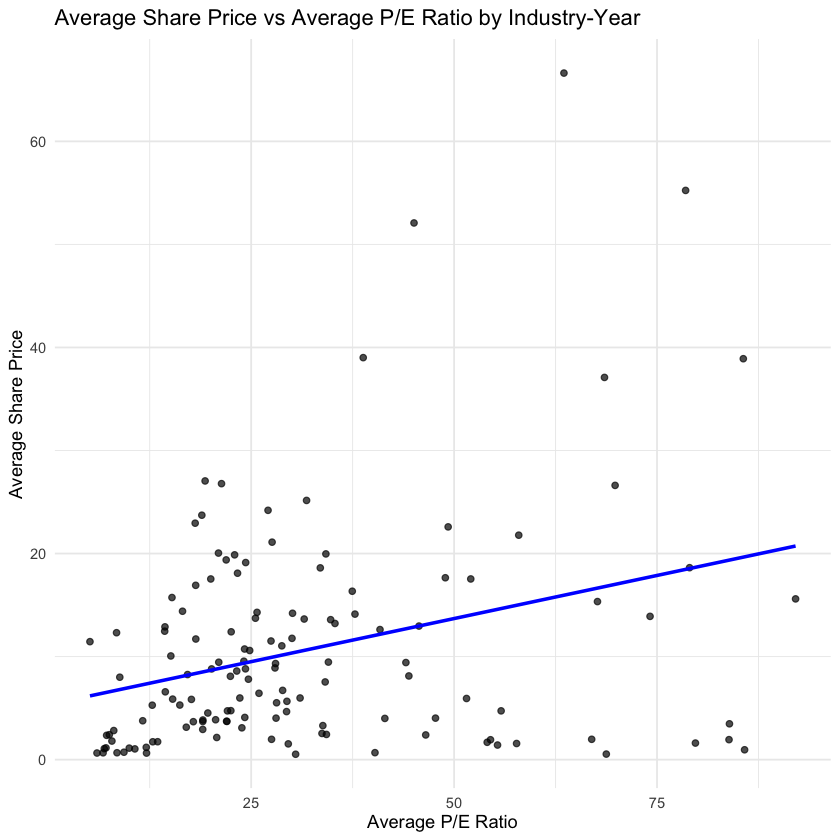

In [29]:
industry_year_summary |>
  filter(n_firms >= 3, avg_pe < 100) |>
  ggplot(aes(x = avg_pe, y = avg_price)) +
  geom_point(alpha = 0.7) +
  geom_smooth(method = "lm", color = "blue", se = FALSE) +
  labs(
    title = "Average Share Price vs Average P/E Ratio by Industry-Year",
    x = "Average P/E Ratio",
    y = "Average Share Price"
  ) +
  theme_minimal()

### Exercise 6

In [30]:
asx_with_pe_inner <-
  asx_prices_tidy |>
  inner_join(
    pe_data,
    by = join_by(gvkey, fyear)
  )

In [31]:
missing_pe <-
  asx_prices_tidy |>
  anti_join(
    pe_data,
    by = join_by(gvkey, fyear)
  )

In [32]:
nrow(asx_prices_tidy)
nrow(asx_with_pe)
nrow(asx_with_pe_inner)
nrow(missing_pe)

[1] 9484

[1] 9484

[1] 2407

[1] 7077

In [33]:
missing_pe |>
  count(fyear)

fyear,n
<dbl>,<int>
2019,1178
2020,1189
2021,1186
2022,1286
2023,1245
2024,993


In [34]:
missing_pe |>
  summarise(
    min_eps = min(eps, na.rm = TRUE),
    max_eps = max(eps, na.rm = TRUE),
    avg_eps = mean(eps, na.rm = TRUE)
  )

min_eps,max_eps,avg_eps
<dbl>,<dbl>,<dbl>
-2267,2.0479,-0.4205366


In [35]:
missing_pe |>
  count(conm) |>
  arrange(desc(n))

conm,n
<chr>,<int>
1414 DEGREES LTD,6
4DS MEMORY LTD,6
5G NETWORKS LIMITED,6
8COMMON LTD,6
ACCELERATE RESOURC,6
ACCENT RESOURCES NL,6
ACROW LIMITED,6
ACRUX LTD,6
ACTINOGEN MEDICAL LTD,6
